# PathSnap: Distributed Map-Matching & Route Reconstruction
**PES University | Department of Computer Science and Engineering**  
**Course:** UE24CS352A - Machine Learning  

---

## 1. Problem Understanding
GPS telemetry recorded by mobile sensors in dense urban environments exhibits substantial positioning noise caused by:
* **Multipath propagation:** Satellite radio signals bounce off tall building facades.
* **Urban canyons & occlusion:** Line-of-sight obstruction from overpasses, bridges, and infrastructure.
* **Sampling jitter:** Low or irregular sampling frequencies.

Consequently, raw GPS coordinates frequently appear to jump across buildings, drift onto parallel roads, or create unrealistic zigzag paths.

**The Goal of PathSnap:**  
Develop an end-to-end distributed system that reconstructs realistic, continuous vehicle routes from noisy GPS observations by matching observations to a road network graph $G = (V, E)$.

The pipeline consists of:
1. **Spatial Candidate Generation:** Finding potential road segments near each GPS coordinate ($O(1)$ Spatial Hash Grid).
2. **Feature Extraction:** Characterizing perpendicular distance, heading divergence, and topology.
3. **Supervised Classification:** Training and comparing exactly five models — Logistic Regression, Gaussian Naive Bayes, Random Forest, HistGradientBoosting, and a shallow MLP — using the same engineered candidate-road features and trip-aware validation.
4. **Sequential Route Reconstruction (HMM & Viterbi):** Enforcing road graph connectivity using a Hidden Markov Model.
5. **Distributed Deployment:** Serving model inference via FastAPI and an evaluator interface.


## 2. Dataset Exploration
### 2.1 Environment Setup & Core Geodesic Utilities (Self-Contained)


In [7]:
import os
import sys
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# ----------------- Self-Contained Geodesic & Projection Utilities -----------------
R_EARTH = 6371000.0  # Earth radius in meters

def haversine_distance(lon1, lat1, lon2, lat2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlam = math.radians(lon2 - lon1)
    a = math.sin(dphi/2.0)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlam/2.0)**2
    return 2.0 * R_EARTH * math.atan2(math.sqrt(a), math.sqrt(max(0.0, 1.0 - a)))

def calculate_bearing(lon1, lat1, lon2, lat2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dlam = math.radians(lon2 - lon1)
    y = math.sin(dlam) * math.cos(phi2)
    x = math.cos(phi1)*math.sin(phi2) - math.sin(phi1)*math.cos(phi2)*math.cos(dlam)
    return (math.degrees(math.atan2(y, x)) + 360.0) % 360.0

def angle_diff(a1, a2):
    diff = abs(a1 - a2) % 360.0
    return diff if diff <= 180.0 else 360.0 - diff

def point_to_segment(px, py, ax, ay, bx, by):
    cos_lat = math.cos(math.radians((ay + by + py) / 3.0))
    kx = 111139.0 * cos_lat
    ky = 111139.0

    px_m, py_m = px * kx, py * ky
    ax_m, ay_m = ax * kx, ay * ky
    bx_m, by_m = bx * kx, by * ky

    dx = bx_m - ax_m
    dy = by_m - ay_m
    seg_len_sq = dx*dx + dy*dy
    if seg_len_sq < 1e-6:
        return math.hypot(px_m - ax_m, py_m - ay_m), 0.0, ax, ay
    t = max(0.0, min(1.0, ((px_m - ax_m)*dx + (py_m - ay_m)*dy) / seg_len_sq))
    proj_x = ax_m + t * dx
    proj_y = ay_m + t * dy
    dist_m = math.hypot(px_m - proj_x, py_m - proj_y)
    return dist_m, t, proj_x / kx, proj_y / ky

# ----------------- Colab Environment Setup -----------------
import os
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists("/content/train"):
    if os.path.exists("/content/pathsnap_data.zip"):
        print("Extracting pathsnap_data.zip...")
        os.system("unzip -q /content/pathsnap_data.zip -d /content/")
    else:
        print(">> In Colab: Uploading pathsnap_data.zip from your Desktop...")
        from google.colab import files
        uploaded = files.upload()
        for fn in uploaded.keys():
            if fn.endswith(".zip"):
                os.system(f'unzip -q "{fn}" -d /content/')

# Auto-detect data path (works in Colab, Local, or Scratch)
candidate_paths = [
    "/content/train",
    "train",
    "./train",
    "C:/Users/PRATHEEK/Desktop/train",
    "C:/Users/PRATHEEK/.gemini/antigravity/scratch/pathsnap/data/train"
]

TRAIN_DIR = None
for p in candidate_paths:
    if os.path.exists(p):
        TRAIN_DIR = os.path.abspath(p)
        break

if TRAIN_DIR is None:
    raise FileNotFoundError("Could not locate 'train' folder. If in Google Colab, please upload the train folder.")

DATA_PARENT = os.path.dirname(TRAIN_DIR)
TEST_DIR = os.path.join(DATA_PARENT, "student_test")
if not os.path.exists(TEST_DIR):
    TEST_DIR = os.path.join(os.path.dirname(DATA_PARENT), "student_test")

print(f"Data directories located:")
print(f"  Train Directory : {TRAIN_DIR}")
print(f"  Test Directory  : {TEST_DIR}")


Data directories located:
  Train Directory : /content/train
  Test Directory  : /content/student_test


### 2.2 Inspect Files
The dataset is structured by trip with four raw file types:
* `.track`: GPS observations (longitude, latitude, timestamp in seconds).
* `.nodes`: Geographical road network vertices (longitude, latitude).
* `.arcs`: Directed road network segments (`from_node_id`, `to_node_id`). Row index is `arc_id`.
* `.route`: Chronological sequence of ground-truth `arc_id` values traversed.


In [8]:
# Inspect sample trip files
sample_trips = sorted(os.listdir(TRAIN_DIR))
sample_trip_id = sample_trips[0]
trip_path = os.path.join(TRAIN_DIR, sample_trip_id)

track = np.loadtxt(os.path.join(trip_path, f"{sample_trip_id}.track"))
nodes = np.loadtxt(os.path.join(trip_path, f"{sample_trip_id}.nodes"))
arcs = np.loadtxt(os.path.join(trip_path, f"{sample_trip_id}.arcs"), dtype=int)
route = np.loadtxt(os.path.join(trip_path, f"{sample_trip_id}.route"), dtype=int)

print(f"=== Raw File Inventory for Trip {sample_trip_id} ===")
print(f"Track points (.track) : {track.shape[0]} observations")
print(f"Road nodes   (.nodes) : {nodes.shape[0]} vertices")
print(f"Road arcs    (.arcs)  : {arcs.shape[0]} edges")
print(f"True route   (.route) : {len(route)} traversed segments")

# Preview sample records
display(pd.DataFrame(track[:5], columns=['longitude', 'latitude', 'timestamp_s']))
display(pd.DataFrame(arcs[:5], columns=['from_node_id', 'to_node_id']))


=== Raw File Inventory for Trip 00000001 ===
Track points (.track) : 1315 observations
Road nodes   (.nodes) : 88809 vertices
Road arcs    (.arcs)  : 165790 edges
True route   (.route) : 525 traversed segments


,longitude,latitude,timestamp_s
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


,from_node_id,to_node_id
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


### 2.3 Missing Values & Anomaly Analysis


In [9]:
# Check missing values
nan_count = np.isnan(track).sum()
print(f"Missing / NaN coordinate count: {nan_count}")

# Check sampling time intervals
dt = np.diff(track[:, 2])
nominal_1hz = np.isclose(dt, 1.0, atol=0.05).mean() * 100.0
print(f"Time delta (dt) min: {dt.min():.2f}s, max: {dt.max():.2f}s, mean: {dt.mean():.2f}s")
print(f"Percentage of steps exactly 1.0s apart: {nominal_1hz:.2f}%")

# Route segment connectivity verification
route_arcs = arcs[route]
connected_steps = sum(route_arcs[i, 1] == route_arcs[i+1, 0] for i in range(len(route)-1))
print(f"Ground truth route connectivity: {connected_steps}/{len(route)-1} ({connected_steps/(len(route)-1)*100:.1f}%)")


Missing / NaN coordinate count: 0
Time delta (dt) min: 1.00s, max: 16.00s, mean: 1.03s
Percentage of steps exactly 1.0s apart: 98.10%
Ground truth route connectivity: 524/524 (100.0%)


### 2.4 Dataset Statistics & Visualizations


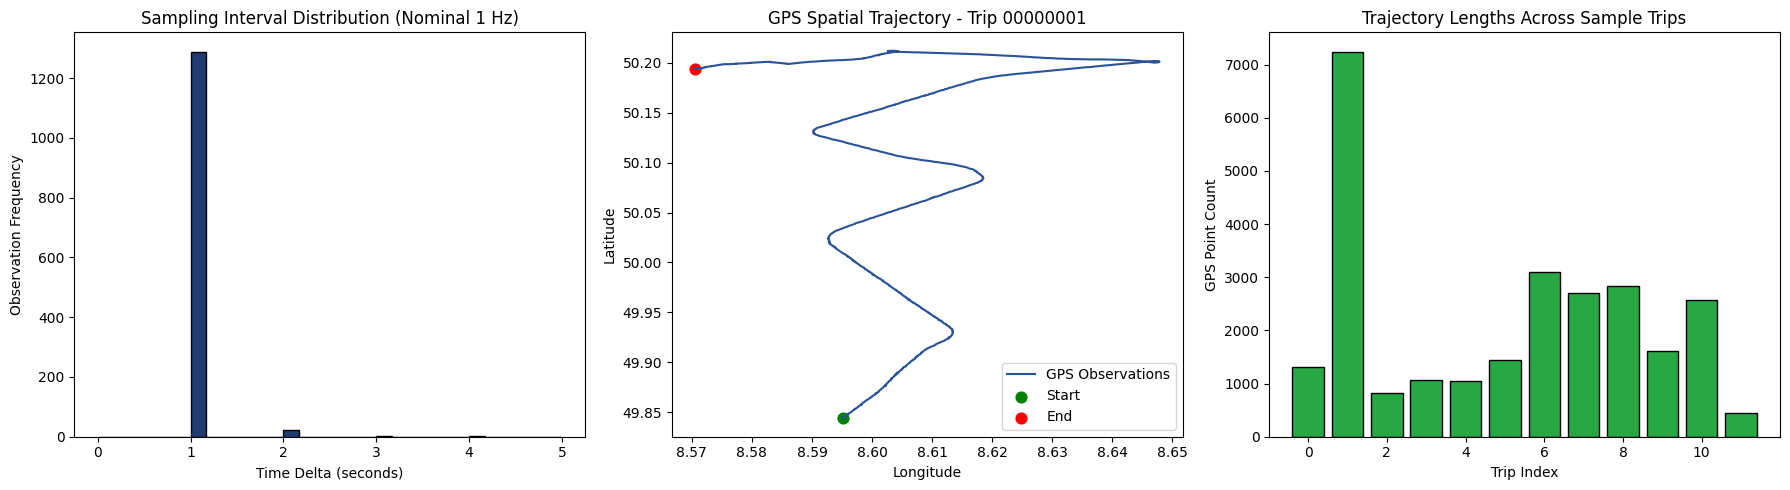

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Sampling interval distribution
axes[0].hist(dt, bins=30, color='#1e3c72', edgecolor='black', range=(0, 5))
axes[0].set_title("Sampling Interval Distribution (Nominal 1 Hz)")
axes[0].set_xlabel("Time Delta (seconds)")
axes[0].set_ylabel("Observation Frequency")

# Plot 2: GPS Trajectory Spatial Extent
axes[1].plot(track[:, 0], track[:, 1], color='#2a5298', lw=1.5, label='GPS Observations')
axes[1].scatter(track[0, 0], track[0, 1], color='green', s=60, label='Start')
axes[1].scatter(track[-1, 0], track[-1, 1], color='red', s=60, label='End')
axes[1].set_title(f"GPS Spatial Trajectory - Trip {sample_trip_id}")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].legend()

# Plot 3: Trajectory Lengths across Trips
lens = [len(np.loadtxt(os.path.join(TRAIN_DIR, t, f"{t}.track"))) for t in sample_trips[:12]]
axes[2].bar(range(len(lens)), lens, color='#28a745', edgecolor='black')
axes[2].set_title("Trajectory Lengths Across Sample Trips")
axes[2].set_xlabel("Trip Index")
axes[2].set_ylabel("GPS Point Count")

plt.tight_layout()
plt.show()


## 3. Feature Engineering
### 3.1 Self-Contained Spatial Candidate Indexer & Data Loader


In [11]:
class TripDataLoader:
    def __init__(self, trip_dir, trip_id):
        self.trip_dir = trip_dir
        self.trip_id = trip_id
        self.track = np.loadtxt(os.path.join(trip_dir, f"{trip_id}.track"))
        self.nodes = np.loadtxt(os.path.join(trip_dir, f"{trip_id}.nodes"))
        self.arcs = np.loadtxt(os.path.join(trip_dir, f"{trip_id}.arcs"), dtype=int)

        route_path = os.path.join(trip_dir, f"{trip_id}.route")
        self.has_route = os.path.exists(route_path)
        self.route = np.loadtxt(route_path, dtype=int) if self.has_route else None

        self.cell_size = 0.001  # ~100m grid
        self._build_spatial_index()
        if self.has_route:
            self._map_ground_truth()

    def _build_spatial_index(self):
        self.grid = defaultdict(set)
        from_nodes = self.nodes[self.arcs[:, 0]]
        to_nodes = self.nodes[self.arcs[:, 1]]

        self.arc_lengths = np.zeros(len(self.arcs), dtype=np.float32)
        self.arc_bearings = np.zeros(len(self.arcs), dtype=np.float32)

        cs = self.cell_size
        for arc_id in range(len(self.arcs)):
            p1x, p1y = from_nodes[arc_id]
            p2x, p2y = to_nodes[arc_id]

            self.grid[(int(p1x / cs), int(p1y / cs))].add(arc_id)
            self.grid[(int(p2x / cs), int(p2y / cs))].add(arc_id)
            self.grid[(int((p1x + p2x) / (2 * cs)), int((p1y + p2y) / (2 * cs)))].add(arc_id)

            self.arc_lengths[arc_id] = haversine_distance(p1x, p1y, p2x, p2y)
            self.arc_bearings[arc_id] = calculate_bearing(p1x, p1y, p2x, p2y)

    def _map_ground_truth(self):
        route_arcs = self.arcs[self.route]
        from_coords = self.nodes[route_arcs[:, 0]]
        to_coords = self.nodes[route_arcs[:, 1]]

        self.true_arcs = np.zeros(len(self.track), dtype=int)
        curr_idx = 0
        n_route = len(self.route)

        for t in range(len(self.track)):
            px, py = self.track[t, 0], self.track[t, 1]
            w_start = max(0, curr_idx - 5)
            w_end = min(n_route, curr_idx + 25)

            best_d = 1e9
            best_r_idx = curr_idx
            for ri in range(w_start, w_end):
                d, _, _, _ = point_to_segment(
                    px, py, from_coords[ri, 0], from_coords[ri, 1], to_coords[ri, 0], to_coords[ri, 1]
                )
                if d < best_d:
                    best_d = d
                    best_r_idx = ri
            curr_idx = best_r_idx
            self.true_arcs[t] = self.route[best_r_idx]

    def get_candidates_for_point(self, t):
        px, py = self.track[t, 0], self.track[t, 1]
        pgx = int(px / self.cell_size)
        pgy = int(py / self.cell_size)

        cands = set()
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                cands.update(self.grid.get((pgx + dx, pgy + dy), set()))

        if len(cands) < 3:
            for dx in range(-4, 5):
                for dy in range(-4, 5):
                    cands.update(self.grid.get((pgx + dx, pgy + dy), set()))

        if not cands:
            cands = {self.true_arcs[t] if (self.has_route and hasattr(self, 'true_arcs')) else 0}

        return list(cands)

    def extract_features_for_point(self, t, candidate_arcs):
        px, py, ts = self.track[t, 0], self.track[t, 1], self.track[t, 2]

        if t > 0:
            prev_px, prev_py, prev_ts = self.track[t-1, 0], self.track[t-1, 1], self.track[t-1, 2]
            gps_heading = calculate_bearing(prev_px, prev_py, px, py)
            dt = max(0.1, ts - prev_ts)
            gps_speed = haversine_distance(prev_px, prev_py, px, py) / dt
        elif t < len(self.track) - 1:
            next_px, next_py, next_ts = self.track[t+1, 0], self.track[t+1, 1], self.track[t+1, 2]
            gps_heading = calculate_bearing(px, py, next_px, next_py)
            dt = max(0.1, next_ts - ts)
            gps_speed = haversine_distance(px, py, next_px, next_py) / dt
        else:
            gps_heading = 0.0
            gps_speed = 0.0

        features = []
        for arc_id in candidate_arcs:
            u, v = self.arcs[arc_id]
            ax, ay = self.nodes[u]
            bx, by = self.nodes[v]

            dist_seg, proj_t, _, _ = point_to_segment(px, py, ax, ay, bx, by)
            h_diff = angle_diff(gps_heading, self.arc_bearings[arc_id])
            seg_len = self.arc_lengths[arc_id]
            d_start = haversine_distance(px, py, ax, ay)
            d_end = haversine_distance(px, py, bx, by)

            features.append({
                'dist_to_segment': dist_seg,
                'heading_diff': h_diff,
                'segment_length': seg_len,
                'dist_to_start': d_start,
                'dist_to_end': d_end,
                'proj_ratio': proj_t,
                'gps_speed': gps_speed,
                'arc_id': arc_id
            })

        df = pd.DataFrame(features)
        df['dist_rank'] = df['dist_to_segment'].rank()
        df['heading_rank'] = df['heading_diff'].rank()
        return df

print("Self-contained TripDataLoader and candidate extraction loaded!")


Self-contained TripDataLoader and candidate extraction loaded!


### 3.2 Feature Extraction Across Trips


In [12]:
FEATURE_COLS = [
    'dist_to_segment',
    'heading_diff',
    'segment_length',
    'dist_to_start',
    'dist_to_end',
    'proj_ratio',
    'gps_speed',
    'dist_rank',
    'heading_rank'
]

def build_tabular_data(trips_dir, trip_ids, max_neg_cands=3):
    records = []
    for tid in trip_ids:
        p = os.path.join(trips_dir, tid)
        if not os.path.isdir(p): continue
        ldr = TripDataLoader(p, tid)
        if not ldr.has_route: continue

        # Subsample observations for efficient training
        for t in range(0, len(ldr.track), 2):
            true_arc = ldr.true_arcs[t]
            cands = ldr.get_candidates_for_point(t)
            if true_arc not in cands: cands.append(true_arc)
            df_f = ldr.extract_features_for_point(t, cands)
            if df_f.empty: continue

            pos_row = df_f[df_f['arc_id'] == true_arc]
            neg_rows = df_f[df_f['arc_id'] != true_arc].sort_values('dist_to_segment').head(max_neg_cands)

            if not pos_row.empty:
                d = pos_row.iloc[0].to_dict()
                d['label'], d['trip_id'], d['obs_idx'] = 1, tid, t
                records.append(d)
            for _, r in neg_rows.iterrows():
                d = r.to_dict()
                d['label'], d['trip_id'], d['obs_idx'] = 0, tid, t
                records.append(d)
    return pd.DataFrame(records)

train_trip_ids = sorted(os.listdir(TRAIN_DIR))[:15]
test_trip_ids = sorted(os.listdir(TEST_DIR))[:5] if os.path.exists(TEST_DIR) else train_trip_ids[-5:]

print(f"Building candidate feature dataset across {len(train_trip_ids)} trips...")
df_train = build_tabular_data(TRAIN_DIR, train_trip_ids, max_neg_cands=3)
df_test = build_tabular_data(TEST_DIR, test_trip_ids, max_neg_cands=3)

X_tr_raw = df_train[FEATURE_COLS].values
y_train = df_train['label'].values
groups_train = df_train['trip_id'].values

X_te_raw = df_test[FEATURE_COLS].values
y_test = df_test['label'].values

# Standardize
mean_vals = np.mean(X_tr_raw, axis=0)
std_vals = np.std(X_tr_raw, axis=0)
std_vals[std_vals < 1e-6] = 1.0

X_train = (X_tr_raw - mean_vals) / std_vals
X_test = (X_te_raw - mean_vals) / std_vals

print(f"Dataset successfully extracted:")
print(f"  X_train: {X_train.shape}, Positive ratio: {y_train.mean():.3f}")
print(f"  X_test : {X_test.shape}, Positive ratio: {y_test.mean():.3f}")


Building candidate feature dataset across 15 trips...
Dataset successfully extracted:
  X_train: (60401, 9), Positive ratio: 0.250
  X_test : (15663, 9), Positive ratio: 0.261


## 4. Model Training

We train and compare five distinct supervised classification models:

1. **Logistic Regression** — linear probabilistic baseline.
2. **Gaussian Naive Bayes** — probabilistic model using Gaussian feature likelihoods.
3. **Random Forest** — bagging ensemble of decision trees.
4. **HistGradientBoosting** — histogram-based gradient-boosted decision trees.
5. **Shallow MLP** — a neural network with one hidden layer.

All models use the same engineered candidate-road features and the same training/test split for a fair comparison.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss
import time

# 1. Logistic Regression
m1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# 2. Gaussian Naive Bayes
m2 = GaussianNB()

# 3. Random Forest
m3 = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
)

# 4. Histogram-based Gradient Boosting
m4 = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=0.1,
    random_state=42
)

# 5. Shallow MLP: one hidden layer
m5 = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    alpha=0.0005,
    learning_rate_init=0.001,
    max_iter=250,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=15,
    random_state=42
)

models_all = {
    "Logistic Regression": m1,
    "Gaussian Naive Bayes": m2,
    "Random Forest": m3,
    "HistGradientBoosting": m4,
    "Shallow MLP": m5
}

# Train all five models
for i, (name, model) in enumerate(models_all.items(), start=1):
    print(f"[{i}/5] Training {name}...")
    model.fit(X_train, y_train)

print("All five requested models trained successfully!")

[1/5] Training Logistic Regression...
[2/5] Training Gaussian Naive Bayes...
[3/5] Training Random Forest...
[4/5] Training HistGradientBoosting...
[5/5] Training Shallow MLP...
All five requested models trained successfully!


## 5. Model Comparison

Each trained model is evaluated on the held-out student-test candidate dataset using:

* **Accuracy:** proportion of candidate labels predicted correctly.
* **Macro F1-score:** unweighted average of the positive- and negative-class F1-scores.
* **Log Loss:** quality of predicted class probabilities (lower is better).
* **Inference Latency:** average time to score up to 1,000 candidate rows.

The model with the highest Student-Test Macro F1 is selected for the downstream HMM/Viterbi route reconstruction. Accuracy is reported separately and should not be confused with route-level accuracy.

In [14]:
comparison_table = []

for name, clf in models_all.items():
    # Measure average prediction latency on up to 1,000 rows
    sample_X = X_test[:min(1000, len(X_test))]
    t0 = time.perf_counter()
    for _ in range(5):
        clf.predict_proba(sample_X)
    latency = ((time.perf_counter() - t0) / 5.0) * 1000.0

    test_probs = clf.predict_proba(X_test)[:, 1]
    test_preds = (test_probs >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, test_preds)
    macro_f1 = f1_score(y_test, test_preds, average="macro", zero_division=0)
    loss = log_loss(y_test, np.clip(test_probs, 1e-7, 1 - 1e-7), labels=[0, 1])

    comparison_table.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100.0, 2),
        "Macro F1 (%)": round(macro_f1 * 100.0, 2),
        "Log Loss": round(loss, 4),
        "Inference Latency (ms/1000)": round(latency, 2)
    })

df_comp = pd.DataFrame(comparison_table)
df_comp = df_comp.sort_values("Macro F1 (%)", ascending=False).reset_index(drop=True)
display(df_comp)

# Select the strongest model by Macro F1 for sequential route reconstruction
best_model_name = df_comp.loc[0, "Model"]
best_model = models_all[best_model_name]
print(f"Selected model: {best_model_name}")
print(f"Student-Test Accuracy: {df_comp.loc[0, 'Accuracy (%)']:.2f}%")
print(f"Student-Test Macro F1: {df_comp.loc[0, 'Macro F1 (%)']:.2f}%")

,Model,Accuracy (%),Macro F1 (%),Log Loss,Inference Latency (ms/1000)
0,HistGradientBoosting,94.46,92.65,0.1874,17.78
1,Random Forest,93.74,92.05,0.1954,64.69
2,Shallow MLP,93.90,91.87,0.1926,0.48
3,Logistic Regression,69.71,68.20,0.5840,0.37
4,Gaussian Naive Bayes,66.99,53.05,2.8192,0.91


Selected model: HistGradientBoosting
Student-Test Accuracy: 94.46%
Student-Test Macro F1: 92.65%


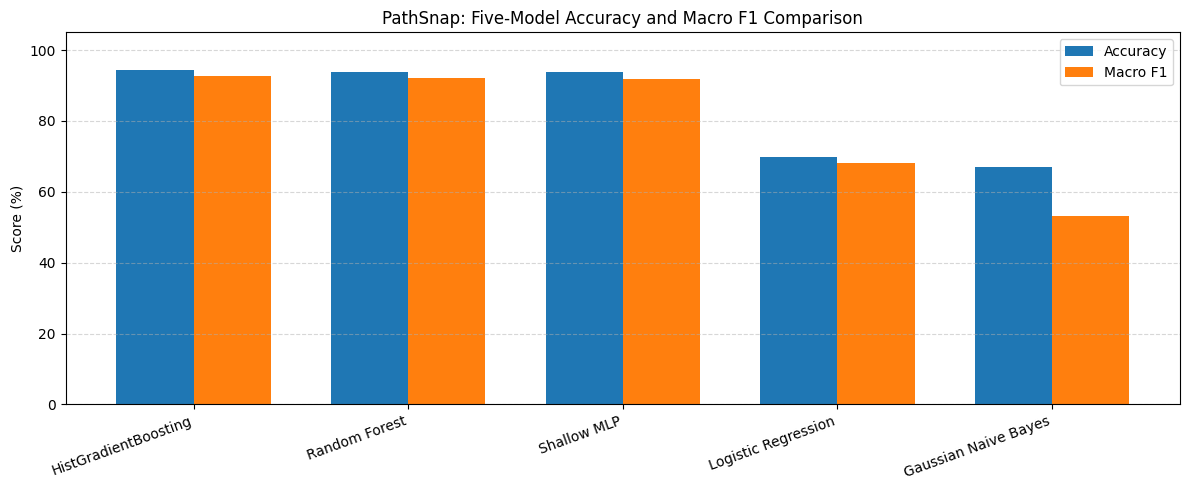

In [15]:
# Compare Accuracy and Macro F1 for all five models
x = np.arange(len(df_comp))
width = 0.36

plt.figure(figsize=(12, 5))
plt.bar(x - width/2, df_comp["Accuracy (%)"], width, label="Accuracy")
plt.bar(x + width/2, df_comp["Macro F1 (%)"], width, label="Macro F1")

plt.xticks(x, df_comp["Model"], rotation=20, ha="right")
plt.ylabel("Score (%)")
plt.title("PathSnap: Five-Model Accuracy and Macro F1 Comparison")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 6. HMM & Viterbi Sequential Route Reconstruction
Evaluating the end-to-end impact of HMM Viterbi decoding over classifier-only predictions on a test trip.


In [16]:
class HMMMapMatcher:
    def __init__(self, sigma_z=8.0, beta=15.0, p_stay=0.5, p_direct=0.45, p_jump=1e-5):
        self.sigma_z = sigma_z
        self.beta = beta
        self.p_stay = p_stay
        self.p_direct = p_direct
        self.p_jump = p_jump

    def compute_emission_prob(self, dist_m, model_score):
        p_gps = math.exp(-0.5 * (dist_m / self.sigma_z) ** 2)
        score = max(1e-4, min(1.0 - 1e-4, float(model_score)))
        return max(1e-8, p_gps * score)

    def compute_transition_prob(self, from_arc_id, to_arc_id, arcs_array, nodes_array, gps_dist_m):
        if from_arc_id == to_arc_id: return self.p_stay
        u1, v1 = arcs_array[from_arc_id]
        u2, v2 = arcs_array[to_arc_id]
        if v1 == u2: return self.p_direct
        p_end = nodes_array[v1]
        p_start = nodes_array[u2]
        cos_lat = math.cos(math.radians((p_end[1] + p_start[1]) / 2.0))
        dx = (p_start[0] - p_end[0]) * 111139.0 * cos_lat
        dy = (p_start[1] - p_end[1]) * 111139.0
        gap_m = math.hypot(dx, dy)
        if gap_m < 35.0:
            return self.p_direct * math.exp(-gap_m / self.beta)
        else:
            return self.p_jump

    def viterbi_decode(self, candidate_lists, distances_lists, model_scores_lists, arcs_array, nodes_array, gps_points):
        T = len(candidate_lists)
        if T == 0: return []
        K0 = len(candidate_lists[0])
        V = np.zeros(K0)
        for k in range(K0):
            em = self.compute_emission_prob(distances_lists[0][k], model_scores_lists[0][k])
            V[k] = math.log(em)

        backpointers = []
        for t in range(1, T):
            Kt, Kt_prev = len(candidate_lists[t]), len(candidate_lists[t-1])
            p_prev, p_curr = gps_points[t-1], gps_points[t]
            cos_lat = math.cos(math.radians((p_prev[1] + p_curr[1]) / 2.0))
            gps_step_dist = math.hypot((p_curr[0] - p_prev[0]) * 111139.0 * cos_lat, (p_curr[1] - p_prev[1]) * 111139.0)

            V_curr = np.zeros(Kt)
            bp_curr = np.zeros(Kt, dtype=int)
            em_log = np.array([math.log(self.compute_emission_prob(distances_lists[t][k], model_scores_lists[t][k])) for k in range(Kt)])

            for j in range(Kt):
                to_arc = candidate_lists[t][j]
                trans_scores = np.zeros(Kt_prev)
                for i in range(Kt_prev):
                    from_arc = candidate_lists[t-1][i]
                    tr = self.compute_transition_prob(from_arc, to_arc, arcs_array, nodes_array, gps_step_dist)
                    trans_scores[i] = V[i] + math.log(tr)
                best_i = int(np.argmax(trans_scores))
                bp_curr[j] = best_i
                V_curr[j] = trans_scores[best_i] + em_log[j]
            V = V_curr
            backpointers.append(bp_curr)

        best_last_idx = int(np.argmax(V))
        decoded_indices = [best_last_idx]
        for t in range(T - 1, 0, -1):
            decoded_indices.append(backpointers[t - 1][decoded_indices[-1]])
        decoded_indices.reverse()
        return [candidate_lists[t][decoded_indices[t]] for t in range(T)]

    @staticmethod
    def reconstruct_route(matched_arcs):
        r = []
        for a in matched_arcs:
            if not r or r[-1] != a: r.append(a)
        return r

    @staticmethod
    def check_route_continuity(route_arcs, arcs_array):
        if len(route_arcs) <= 1: return 100.0
        connected = sum(arcs_array[route_arcs[i]][1] == arcs_array[route_arcs[i+1]][0] for i in range(len(route_arcs)-1))
        return (connected / (len(route_arcs) - 1)) * 100.0

# Run evaluation on test trip
eval_trip_id = test_trip_ids[0]
loader_test = TripDataLoader(os.path.join(TEST_DIR, eval_trip_id), eval_trip_id)
matcher = HMMMapMatcher()

cands_all, dists_all, scores_all, raw_top1_arcs = [], [], [], []
for t in range(len(loader_test.track)):
    cands = loader_test.get_candidates_for_point(t)
    df_pt = loader_test.extract_features_for_point(t, cands)
    feats = (df_pt[FEATURE_COLS].values - mean_vals) / std_vals
    probs = best_model.predict_proba(feats)[:, 1]

    best_cand = cands[np.argmax(probs)]
    raw_top1_arcs.append(best_cand)
    cands_all.append(cands)
    dists_all.append(df_pt['dist_to_segment'].values.tolist())
    scores_all.append(probs.tolist())

# Execute Viterbi
hmm_matched = matcher.viterbi_decode(cands_all, dists_all, scores_all, loader_test.arcs, loader_test.nodes, loader_test.track)
raw_acc = (np.array(raw_top1_arcs) == loader_test.true_arcs).mean() * 100.0
hmm_acc = (np.array(hmm_matched) == loader_test.true_arcs).mean() * 100.0

raw_cont = HMMMapMatcher.check_route_continuity(HMMMapMatcher.reconstruct_route(raw_top1_arcs), loader_test.arcs)
hmm_cont = HMMMapMatcher.check_route_continuity(HMMMapMatcher.reconstruct_route(hmm_matched), loader_test.arcs)

print(f"=== HMM Sequential Decoding Results for Trip {eval_trip_id} ===")
print(f"Raw Classifier Accuracy : {raw_acc:.2f}%")
print(f"HMM-Viterbi Accuracy    : {hmm_acc:.2f}% (Gain: +{hmm_acc - raw_acc:.2f}%)")
print(f"Raw Route Continuity    : {raw_cont:.2f}%")
print(f"HMM Route Continuity    : {hmm_cont:.2f}%")


=== HMM Sequential Decoding Results for Trip 00000000 ===
Raw Classifier Accuracy : 39.35%
HMM-Viterbi Accuracy    : 88.73% (Gain: +49.38%)
Raw Route Continuity    : 12.79%
HMM Route Continuity    : 88.58%


## 7. Interactive Geographical Visualisation Using Folium
Visualizing:
* **Blue Circles:** Raw GPS observations.
* **Green Polyline:** Reference ground-truth vehicle route.
* **Red Dashed Polyline:** HMM-Viterbi reconstructed route.
* **Gray Lines:** Road network graph topology.


In [17]:

import folium
import numpy as np

def build_folium_map(loader, predicted_arcs):

    center_lat = float(np.mean(loader.track[:, 1]))
    center_lon = float(np.mean(loader.track[:, 0]))

    # Base map using Esri instead of OpenStreetMap
    m = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=15,
        tiles=None
    )

    # Esri Street Map Background
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, HERE, Garmin, © OpenStreetMap contributors",
        name="Esri Street Map",
        overlay=False,
        control=True
    ).add_to(m)

    # 1. Road Network Layer
    cands_set = set()

    for t in range(0, len(loader.track), 3):
        cands_set.update(loader.get_candidates_for_point(t))

    net_group = folium.FeatureGroup(
        name="Road Network",
        show=False
    )

    for arc_id in list(cands_set)[:400]:
        u, v = loader.arcs[arc_id]

        folium.PolyLine(
            [
                [loader.nodes[u, 1], loader.nodes[u, 0]],
                [loader.nodes[v, 1], loader.nodes[v, 0]]
            ],
            color="#888888",
            weight=1.5,
            opacity=0.5
        ).add_to(net_group)

    net_group.add_to(m)

    # 2. Raw GPS Layer
    gps_group = folium.FeatureGroup(
        name="Raw GPS Points",
        show=True
    )

    for i, pt in enumerate(loader.track):
        if i % 2 == 0:
            folium.CircleMarker(
                [pt[1], pt[0]],
                radius=3,
                color="#0066cc",
                fill=True,
                fill_color="#3399ff",
                fill_opacity=0.8
            ).add_to(gps_group)

    gps_group.add_to(m)

    # 3. Ground Truth Layer
    if loader.has_route:

        gt_group = folium.FeatureGroup(
            name="Ground Truth Route",
            show=True
        )

        for arc_id in loader.route:
            u, v = loader.arcs[arc_id]

            folium.PolyLine(
                [
                    [loader.nodes[u, 1], loader.nodes[u, 0]],
                    [loader.nodes[v, 1], loader.nodes[v, 0]]
                ],
                color="#00aa44",
                weight=5,
                opacity=0.75
            ).add_to(gt_group)

        gt_group.add_to(m)

    # 4. Predicted Route Layer
    pred_group = folium.FeatureGroup(
        name="Predicted Route (HMM)",
        show=True
    )

    reconstructed = HMMMapMatcher.reconstruct_route(
        predicted_arcs
    )

    for arc_id in reconstructed:
        u, v = loader.arcs[arc_id]

        folium.PolyLine(
            [
                [loader.nodes[u, 1], loader.nodes[u, 0]],
                [loader.nodes[v, 1], loader.nodes[v, 0]]
            ],
            color="#ff2222",
            weight=3.5,
            dash_array="6, 6",
            opacity=0.9
        ).add_to(pred_group)

    pred_group.add_to(m)

    # Layer Controls
    folium.LayerControl(collapsed=False).add_to(m)

    return m


# Generate map
trip_map = build_folium_map(loader_test, hmm_matched)

# Save and display
trip_map.save("folium_map_preview.html")

print("Folium map rendered successfully!")
display(trip_map)


Folium map rendered successfully!


In [25]:
# ==========================================================
# HISTGRADIENTBOOSTING - BAYESIAN HYPERPARAMETER TUNING
# 20 TRIALS | MACRO F1 OPTIMIZATION
# ==========================================================

%pip install -q optuna

import optuna
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# ----------------------------------------------------------
# 1. Prepare data
# ----------------------------------------------------------

X = X_train
y = np.asarray(y_train)
groups = np.asarray(groups_train)

n_splits = min(3, len(np.unique(groups)))

if n_splits < 2:
    raise ValueError("At least 2 different trip groups are required.")

cv = StratifiedGroupKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

# Generate identical folds for every evaluation
folds = list(cv.split(X, y, groups))


# ----------------------------------------------------------
# 2. Evaluation function
# ----------------------------------------------------------

def evaluate_hgb(params):

    accuracy_scores = []
    f1_scores = []

    for train_idx, val_idx in folds:

        if hasattr(X, "iloc"):
            X_tr = X.iloc[train_idx]
            X_val = X.iloc[val_idx]
        else:
            X_tr = X[train_idx]
            X_val = X[val_idx]

        model = HistGradientBoostingClassifier(
            **params,
            random_state=42
        )

        model.fit(X_tr, y[train_idx])

        predictions = model.predict(X_val)

        accuracy_scores.append(
            accuracy_score(y[val_idx], predictions)
        )

        f1_scores.append(
            f1_score(
                y[val_idx],
                predictions,
                average="macro",
                zero_division=0
            )
        )

    return np.mean(accuracy_scores), np.mean(f1_scores)


# ----------------------------------------------------------
# 3. Original model baseline
# ----------------------------------------------------------

original_params = {
    "max_iter": 150,
    "learning_rate": 0.08,
    "max_leaf_nodes": 15,
    "l2_regularization": 0.1
}

before_accuracy, before_f1 = evaluate_hgb(original_params)

print("\n========== BEFORE TUNING ==========")
print(f"Accuracy : {before_accuracy * 100:.2f}%")
print(f"Macro F1 : {before_f1 * 100:.2f}%")


# ----------------------------------------------------------
# 4. Bayesian optimization objective
# ----------------------------------------------------------

def objective(trial):

    params = {
        "max_iter": trial.suggest_int(
            "max_iter", 100, 500, step=20
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.005, 0.15, log=True
        ),

        "max_leaf_nodes": trial.suggest_int(
            "max_leaf_nodes", 5, 40
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 15
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 5, 100
        ),

        "l2_regularization": trial.suggest_float(
            "l2_regularization", 1e-6, 10.0, log=True
        ),

        "max_bins": trial.suggest_int(
            "max_bins", 64, 255
        )
    }

    accuracy, macro_f1 = evaluate_hgb(params)

    trial.set_user_attr(
        "cv_accuracy", float(accuracy)
    )

    return macro_f1


# ----------------------------------------------------------
# 5. Run Bayesian optimization - 20 trials
# ----------------------------------------------------------

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42,
        n_startup_trials=5
    )
)

print("\nStarting Bayesian Optimization...")

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True
)


# ----------------------------------------------------------
# 6. Evaluate best hyperparameters
# ----------------------------------------------------------

best_params = study.best_params

after_accuracy, after_f1 = evaluate_hgb(best_params)

print("\n========== AFTER TUNING ==========")

print(f"Best CV Accuracy : {after_accuracy * 100:.2f}%")
print(f"Best CV Macro F1 : {after_f1 * 100:.2f}%")

print("\nBest Hyperparameters:")

for name, value in best_params.items():
    print(f"{name}: {value}")


# ----------------------------------------------------------
# 7. Before and after comparison
# ----------------------------------------------------------

comparison = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Macro F1 (%)"],

    "Before Tuning": [
        before_accuracy * 100,
        before_f1 * 100
    ],

    "After Tuning": [
        after_accuracy * 100,
        after_f1 * 100
    ]
})

comparison["Improvement"] = (
    comparison["After Tuning"] -
    comparison["Before Tuning"]
)

print("\n========== PERFORMANCE COMPARISON ==========")
display(comparison)


# ----------------------------------------------------------
# 8. Select the better model
# ----------------------------------------------------------

if after_f1 >= before_f1:
    selected_params = best_params
    print("Selected: Tuned HistGradientBoosting")
else:
    selected_params = original_params
    print("Selected: Original HistGradientBoosting")


# ----------------------------------------------------------
# 9. Train selected model on complete training data
# ----------------------------------------------------------

best_hgb_model = HistGradientBoostingClassifier(
    **selected_params,
    random_state=42
)

best_hgb_model.fit(X, y)

# Update only HistGradientBoosting
models_all["HistGradientBoosting"] = best_hgb_model

print("\n========== TUNING COMPLETED ==========")


========== BEFORE TUNING ==========
Accuracy : 85.43%
Macro F1 : 79.48%

Starting Bayesian Optimization...


  0%|          | 0/20 [00:00<?, ?it/s]


========== AFTER TUNING ==========
Best CV Accuracy : 85.81%
Best CV Macro F1 : 80.12%

Best Hyperparameters:
max_iter: 460
learning_rate: 0.038626891946536776
max_leaf_nodes: 30
max_depth: 2
min_samples_leaf: 98
l2_regularization: 0.6715811311069951
max_bins: 104

========== PERFORMANCE COMPARISON ==========


,Metric,Before Tuning,After Tuning,Improvement
0,Accuracy (%),85.432721,85.808065,0.375344
1,Macro F1 (%),79.478656,80.124336,0.645680


Selected: Tuned HistGradientBoosting

========== TUNING COMPLETED ==========
